# Notebook 03 – Feature Engineering and Exploratory Data Analysis (EDA)

## What is this notebook for?
We create useful features from the past (lag prices) and explore the data with charts.  
We never use information from the same month or the future – that would be leakage.

## Why do we need this stage?
- Lag features (last month, last year) are the strongest predictors of next month’s price.
- Charts help us see trends, seasonality and differences between markets.


## Step 3.1 – Load the cleaned panel


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

wide = pd.read_csv('../data/cleaned/uganda_maize_beans_retail_panel.csv', parse_dates=['date'])
wide = wide.sort_values(['market', 'date']).reset_index(drop=True)
print("Loaded panel shape:", wide.shape)


Loaded panel shape: (1233, 9)


## Step 3.2 – Create lag features (only past values)


In [2]:
def add_lags(group, target_col, lags=[1, 2, 3, 6, 12]):
    for lag in lags:
        group[f'{target_col}_lag{lag}'] = group[target_col].shift(lag)
    group[f'{target_col}_roll3'] = group[target_col].shift(1).rolling(window=3, min_periods=1).mean()
    return group

parts = []
for market_name, group in wide.groupby('market'):
    g = group.copy()
    g = add_lags(g, 'maize_price')
    g = add_lags(g, 'beans_price')
    parts.append(g)

df = pd.concat(parts).sort_values(['market', 'date']).reset_index(drop=True)
df['month_sin'] = np.sin(2 * np.pi * df['month'] / 12)
df['month_cos'] = np.cos(2 * np.pi * df['month'] / 12)

print("Shape after adding lags:", df.shape)
print("New columns:", [c for c in df.columns if 'lag' in c or 'roll' in c or 'sin' in c or 'cos' in c])


Shape after adding lags: (1233, 23)
New columns: ['maize_price_lag1', 'maize_price_lag2', 'maize_price_lag3', 'maize_price_lag6', 'maize_price_lag12', 'maize_price_roll3', 'beans_price_lag1', 'beans_price_lag2', 'beans_price_lag3', 'beans_price_lag6', 'beans_price_lag12', 'beans_price_roll3', 'month_sin', 'month_cos']


## Step 3.3 – Graph 1: Yearly average price trend


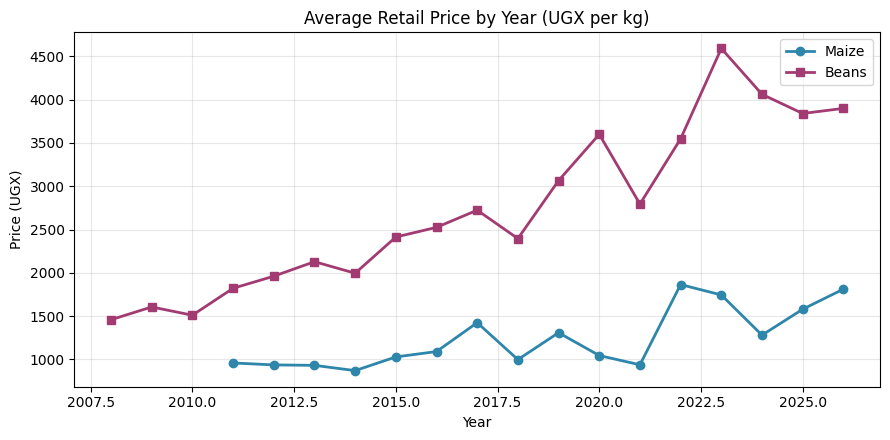

      maize_price  beans_price
year                          
2008          NaN       1459.0
2009          NaN       1607.0
2010          NaN       1511.0
2011        960.0       1822.0
2012        938.0       1962.0
2013        932.0       2129.0
2014        872.0       1996.0
2015       1030.0       2414.0
2016       1092.0       2526.0
2017       1425.0       2724.0
2018        999.0       2396.0
2019       1309.0       3066.0
2020       1046.0       3600.0
2021        939.0       2795.0
2022       1865.0       3549.0
2023       1745.0       4592.0
2024       1281.0       4062.0
2025       1580.0       3840.0
2026       1812.0       3900.0


In [3]:
yearly = df.groupby('year')[['maize_price', 'beans_price']].mean()
plt.figure(figsize=(9, 4.5))
plt.plot(yearly.index, yearly['maize_price'], marker='o', color='#2E86AB', lw=2, label='Maize')
plt.plot(yearly.index, yearly['beans_price'], marker='s', color='#A23B72', lw=2, label='Beans')
plt.title('Average Retail Price by Year (UGX per kg)')
plt.xlabel('Year'); plt.ylabel('Price (UGX)'); plt.legend(); plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('../figures/03_yearly_price_trend.png', dpi=120, bbox_inches='tight')
plt.show()
print(yearly.round(0))


## Step 3.4 – Graph 2: Seasonality by month of year


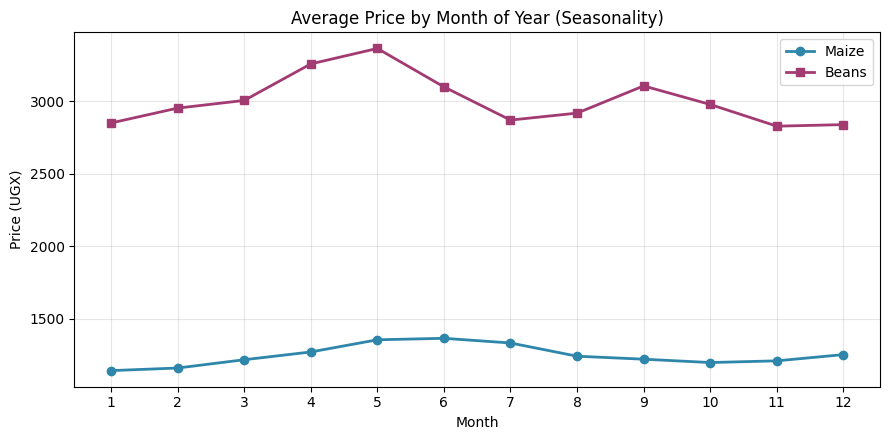

In [4]:
monthly = df.groupby('month')[['maize_price', 'beans_price']].mean()
plt.figure(figsize=(9, 4.5))
plt.plot(monthly.index, monthly['maize_price'], 'o-', color='#2E86AB', lw=2, label='Maize')
plt.plot(monthly.index, monthly['beans_price'], 's-', color='#A23B72', lw=2, label='Beans')
plt.title('Average Price by Month of Year (Seasonality)')
plt.xlabel('Month'); plt.ylabel('Price (UGX)'); plt.xticks(range(1, 13))
plt.legend(); plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('../figures/03_seasonality_by_month.png', dpi=120, bbox_inches='tight')
plt.show()


## Step 3.5 – Graph 3: Correlation heatmap of lag features


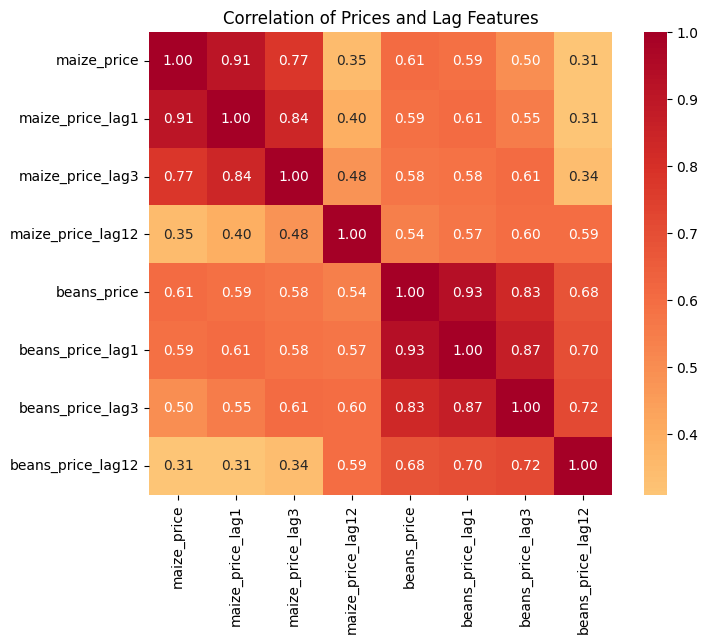

In [5]:
corr_cols = ['maize_price', 'maize_price_lag1', 'maize_price_lag3', 'maize_price_lag12',
             'beans_price', 'beans_price_lag1', 'beans_price_lag3', 'beans_price_lag12']
corr = df[corr_cols].corr()
plt.figure(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdYlBu_r', center=0, square=True)
plt.title('Correlation of Prices and Lag Features')
plt.tight_layout()
plt.savefig('../figures/03_correlation_heatmap.png', dpi=120, bbox_inches='tight')
plt.show()


## Step 3.6 – Graph 4: Lag-1 scatter plots


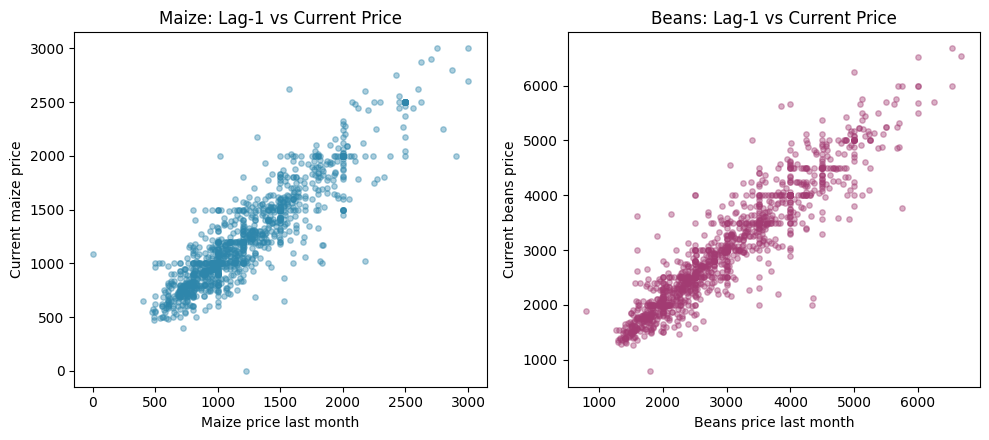

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
axes[0].scatter(df['maize_price_lag1'], df['maize_price'], alpha=0.4, c='#2E86AB', s=15)
axes[0].set_xlabel('Maize price last month'); axes[0].set_ylabel('Current maize price')
axes[0].set_title('Maize: Lag-1 vs Current Price')
axes[1].scatter(df['beans_price_lag1'], df['beans_price'], alpha=0.4, c='#A23B72', s=15)
axes[1].set_xlabel('Beans price last month'); axes[1].set_ylabel('Current beans price')
axes[1].set_title('Beans: Lag-1 vs Current Price')
plt.tight_layout()
plt.savefig('../figures/03_lag1_scatter.png', dpi=120, bbox_inches='tight')
plt.show()


## Step 3.7 – Save the file with lag features


In [7]:
df.to_csv('../data/processed/uganda_maize_beans_with_lags.csv', index=False)
print("Saved: data/processed/uganda_maize_beans_with_lags.csv")


Saved: data/processed/uganda_maize_beans_with_lags.csv
